In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder, StandardScaler

---

In [ ]:
candidates = [
    Path("Thursday-WorkingHours-Morning-WebAttacks.csv")
]

for p in candidates:
    if p.exists():
        csv_path = p
        break
else:
    raise FileNotFoundError(
        "Dataset not found. Place 'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv' "
        "in the notebook directory or update the path."
    )

df = pd.read_csv(csv_path)
print("Total rows:", df.shape[0], " | Total columns:", df.shape[1])
df.head()

Total rows: 170366  | Total columns: 79


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,389,113095465,48,24,9668,10012,403,0,201.416667,203.548293,...,32,203985.500,5.758373e+05,1629110,379,13800000.0,4.277541e+06,16500000,6737603,BENIGN
1,389,113473706,68,40,11364,12718,403,0,167.117647,171.919413,...,32,178326.875,5.034269e+05,1424245,325,13800000.0,4.229413e+06,16500000,6945512,BENIGN
2,0,119945515,150,0,0,0,0,0,0.000000,0.000000,...,0,6909777.333,1.170000e+07,20400000,6,24400000.0,2.430000e+07,60100000,5702188,BENIGN
3,443,60261928,9,7,2330,4221,1093,0,258.888889,409.702161,...,20,0.000,0.000000e+00,0,0,0.0,0.000000e+00,0,0,BENIGN
4,53,269,2,2,102,322,51,51,51.000000,0.000000,...,32,0.000,0.000000e+00,0,0,0.0,0.000000e+00,0,0,BENIGN


---

In [3]:
df.columns = df.columns.str.strip()

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

print("Shape of the cleaned DataFrame:", df.shape)

Shape of the cleaned DataFrame: (164179, 79)


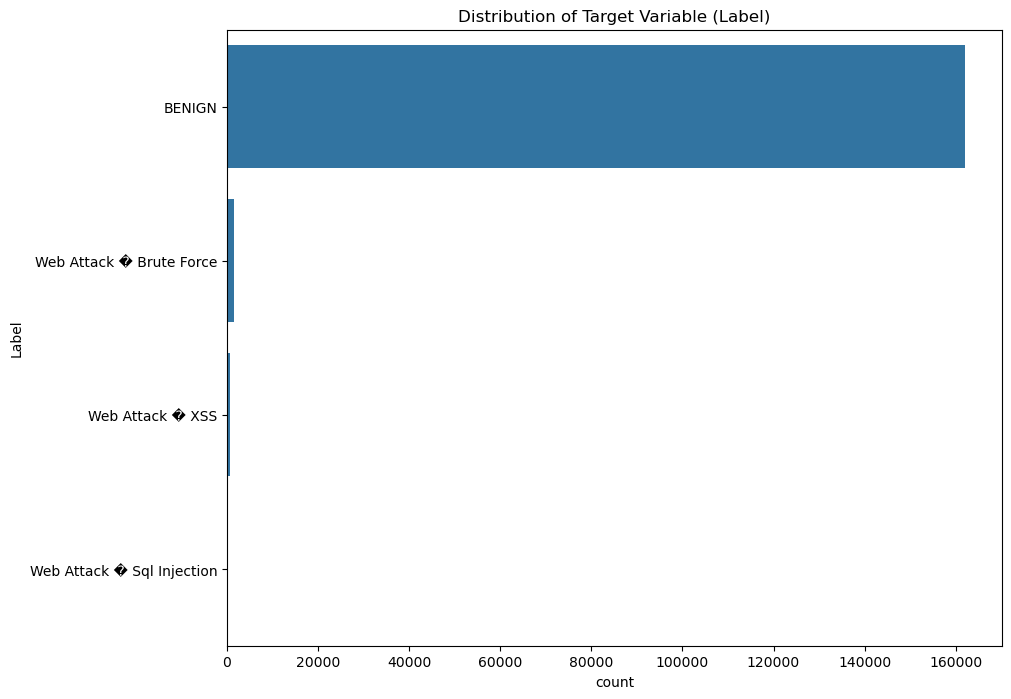

Value counts for 'Label' column:
Label
BENIGN                        162036
Web Attack � Brute Force        1470
Web Attack � XSS                 652
Web Attack � Sql Injection        21
Name: count, dtype: int64


In [4]:
plt.figure(figsize=(10, 8))
sns.countplot(y='Label', data=df)
plt.title('Distribution of Target Variable (Label)')
plt.show()

print("Value counts for 'Label' column:")
print(df['Label'].value_counts())


---

In [5]:
X = df.drop('Label', axis=1)
y = df['Label']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42)

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

print("Model training complete.")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

Model training complete.
X_train shape: (114925, 78)
X_test shape: (49254, 78)


In [6]:
y_pred = dt_model.predict(X_test)

report = classification_report(y_test, y_pred, target_names=le.classes_)
print(report)

                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00     48646
  Web Attack � Brute Force       0.77      0.73      0.75       434
Web Attack � Sql Injection       0.30      0.60      0.40         5
          Web Attack � XSS       0.39      0.42      0.40       169

                  accuracy                           1.00     49254
                 macro avg       0.61      0.69      0.64     49254
              weighted avg       1.00      1.00      1.00     49254

